### Build a Basic Chatbot

Components of LangGraph
1. Nodes: Individual functions or tasks that perform operations, such as calling an LLM or executing a tool.
2. Edges: Connections between nodes that define the workflow and determine which node executes next.
3. State: Shared data that stores and carries information between nodes throughout the graph execution.

In [2]:
from typing import Annotated 
# Annotated is used to attach additional information or metadata to a data type.
# In LangGraph, it is commonly used to define how state values should be updated.
from typing_extensions import TypedDict #TypedDict is used to define the structure of a dictionary
from langgraph.graph import StateGraph,START,END
# StateGraph
# - Used to create a graph-based workflow.
# - It manages nodes, edges, and shared state.
from langgraph.graph.message import add_messages
# add_messages is a message reducer.
# It controls how messages are updated in the graph's state.
# By default, it appends new messages to existing messages instead of replacing the entire list.
# It also handles message updates when messages have matching IDs.


In [8]:
# Define a class named State using TypedDict.
# TypedDict specifies the structure of the dictionary and the types of its values.
class State(TypedDict):

    
    # It appends new messages to existing messages instead of replacing the entire list.
    messages: Annotated[list, add_messages]
# My graph will maintain a state containing a messages field.




In [5]:
import os
from dotenv import load_dotenv
load_dotenv()


True

In [4]:
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain.chat_models import init_chat_model
llm=ChatGoogleGenerativeAI( model="gemini-3.5-flash")


In [7]:
## Node Functionality
def chatbot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}
# #But how does state get its value?

# LangGraph provides it automatically! When the graph executes this node, it passes the current state as the function argument.


In [9]:
graph_builder = StateGraph(State)
#Here, you're telling LangGraph to use the State structure for managing information throughout the workflow.
graph_builder.add_node("llmchatbot",chatbot)
graph_builder.add_edge(START,"llmchatbot")
graph_builder.add_edge("llmchatbot",END)


#compile the graph
graph=graph_builder.compile()




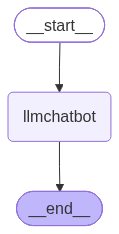

In [11]:
# Import Image to display image files or image data inside Jupyter Notebook.
from IPython.display import Image, display

# Use try to execute the code and catch any errors that may occur.
try:
    # Get the graph structure, convert it into a Mermaid PNG image,
    # and display that image inside the Jupyter Notebook.
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [12]:
graph.invoke({"messages":"hi"})

{'messages': [HumanMessage(content='hi', additional_kwargs={}, response_metadata={}, id='6a9b32de-6165-44c8-98c6-ae68bca2baec'),
  AIMessage(content=[{'type': 'text', 'text': 'Hello! How can I help you today?', 'extras': {'signature': 'Et4GCtsGAWkUfRPRSVEq4+gmi3/CowdhN/UEnLDicZT4lbP7fHe9uDoARE1V5lpUFW59o0K+rck/CnVhHB4AI2sGHPKm810TKvoEQwDJO6yr3s0rcbr5IcXU1Sp3q1iksy4BJrT9Svird6fR41GnS9i75AlNuL89JMqUZuFM8wFyAjXgfGvxUWJ9iRbfFG1hEot+hoO4hisq6MKk91EorgMjFCko5ZBdbD9aCNYjmWHK54ANn2lxH6redgzmSoSNqXMkUYoWyCBeJGtnuEeoxD2g+xErNA6tY9FFj40ImsWRi+0S9kC841n1CYqKBzCqAAr9Wn48v3/On7IF4NtWuhy/4O3JtRqDkAzT4tiE1LXzKTdF1rtrMupkVWyWOLPLl/8Ijx55UeU9ocWbC2OY8XzQlIHumurXw7PHRg4Q83U2LHAqonDJ0vgTz3gLXxy+JwyzAGDN3sjot9NLFGvgYOyHHiZIzatxVayFvcrgztvBuOG4t9Pa4DjnySe3tHh2yy5lMDZpNXGbTD1iQ9EmPmcCbbb5+WTXFOP/bHBGAjUMrTEosvf2TQH66NLyoJNEdfKGfdKl6ZipEWzAu47LkbP4Oi+gXfi7Vlwsi61znAvH1+R6c+vAN7feFOWPrIQMXYT+M1x+7NTZV34Dolw5/jnx0DH1bDMrTwC+b5ogQh6DuiyP4buvKnjTf3N69Jl7SbQ7gwz5rkG9LNPEWcpAusiEX/Avl3rbg3h15wDO4YpDOuEpt5RH5HpIHV6L